In [1]:
import pandas as pd
import numpy as np


In [2]:
data=pd.read_excel('IPL Dataset.xlsm')

In [3]:
data.head()

,Jersey No,Player,Matches,Inns,Not Out,Runs,Highest Score,Avg,Balls faced,Strike rate,100,50,4s,6s
0,1,KL Rahul,14,14,2,670,132*,55.83,518,129.34,1,5,58,23
1,2,Shikhar Dhawan,17,17,3,618,106*,44.14,427,144.73,2,4,67,12
2,3,David Warner,16,16,2,548,85*,39.14,407,134.64,0,4,52,14
3,4,Shreyas Iyer,17,17,2,519,88*,34.60,421,123.27,0,3,40,16
4,5,Ishan Kishan,14,13,4,516,99,57.33,354,145.76,0,4,36,30


In [4]:
data.columns

Index([    'Jersey No',        'Player',       'Matches',          'Inns',
             'Not Out',          'Runs', 'Highest Score',           'Avg',
         'Balls faced',   'Strike rate',             100,              50,
                  '4s',            '6s'],
      dtype='object')

In [5]:
data['Matches'].max()

np.int64(17)

#  Q1. What is the maximum number of matches played by an individual player in a season? Print the player name along with the number of matched played.


In [6]:
result=data[data['Matches']==data['Matches'].max()]
print(result[['Player','Matches']])

            Player  Matches
1   Shikhar Dhawan       17
3     Shreyas Iyer       17
19  Marcus Stoinis       17
67   Kagiso Rabada       17


# Q2. Top 2 players with maximum Average who have scored atleast 2 half centuries ?

In [7]:
filtered_data=data[data[50]>=2]
sorted_data = filtered_data.sort_values(by='Avg', ascending=False)
result = sorted_data.head(2)
print(result[['Player', 'Avg']])

             Player    Avg
36  Wriddhiman Saha  71.33
4      Ishan Kishan  57.33


# Q3. Create 2 new columns based on Player name. First column will have first name and second column will have last name. Eg: for the player Shikhar Dhawan, Shikhar will be the first name and Dhawan will be the last name.


In [8]:
data['First Name']=data['Player'].str.split(' ').str[0]
data['First Name']

0             KL
1        Shikhar
2          David
3        Shreyas
4          Ishan
         ...    
128      Khaleel
129     Arshdeep
130       Daniel
131    Shreevats
132        Trent
Name: First Name, Length: 133, dtype: object

In [9]:
data.columns

Index([    'Jersey No',        'Player',       'Matches',          'Inns',
             'Not Out',          'Runs', 'Highest Score',           'Avg',
         'Balls faced',   'Strike rate',             100,              50,
                  '4s',            '6s',    'First Name'],
      dtype='object')

In [10]:
data['Last Name']=data['Player'].str.split(' ').str[1]
data['Last Name']

0        Rahul
1       Dhawan
2       Warner
3         Iyer
4       Kishan
        ...   
128      Ahmed
129      Singh
130       Sams
131    Goswami
132      Boult
Name: Last Name, Length: 133, dtype: object

In [11]:
data[['Player','First Name','Last Name']]

,Player,First Name,Last Name
0,KL Rahul,KL,Rahul
1,Shikhar Dhawan,Shikhar,Dhawan
2,David Warner,David,Warner
3,Shreyas Iyer,Shreyas,Iyer
4,Ishan Kishan,Ishan,Kishan
...,...,...,...
128,Khaleel Ahmed,Khaleel,Ahmed
129,Arshdeep Singh,Arshdeep,Singh
130,Daniel Sams,Daniel,Sams
131,Shreevats Goswami,Shreevats,Goswami


# Q4. Create a new column (Cleaned_Highest_score) based on Highest score variable. Remove the Asterik(*) mark and convert the data type into INT.

In [12]:
data['Cleaned_Highest_score'] = (
    data['Highest Score']
    .astype(str)
    .str.replace('*', '', regex=False)
    .astype(int)
)

In [13]:
data['Cleaned_Highest_score'].dtype

dtype('int64')

# Q5. Print the total number of centuries scored in the entire season.

In [14]:
print("Total Centuries:", data[100].sum())

Total Centuries: 5


# Q6. Print all the player names whose strike rate is less than the average strike rate of all players in entire season. Print the player name, his strike rate and average strike rate

In [15]:
avg_strike_rate=data['Strike rate'].mean()
result=data[data['Strike rate']<avg_strike_rate]
result['Average Strike Rate']=avg_strike_rate
#print(result[['Player','Strike rate']])
type(result)

pandas.DataFrame

In [16]:
result.columns

Index([            'Jersey No',                'Player',
                     'Matches',                  'Inns',
                     'Not Out',                  'Runs',
               'Highest Score',                   'Avg',
                 'Balls faced',           'Strike rate',
                           100,                      50,
                          '4s',                    '6s',
                  'First Name',             'Last Name',
       'Cleaned_Highest_score',   'Average Strike Rate'],
      dtype='object')

# Q7. Please check the correlation between the features and create a heat map.

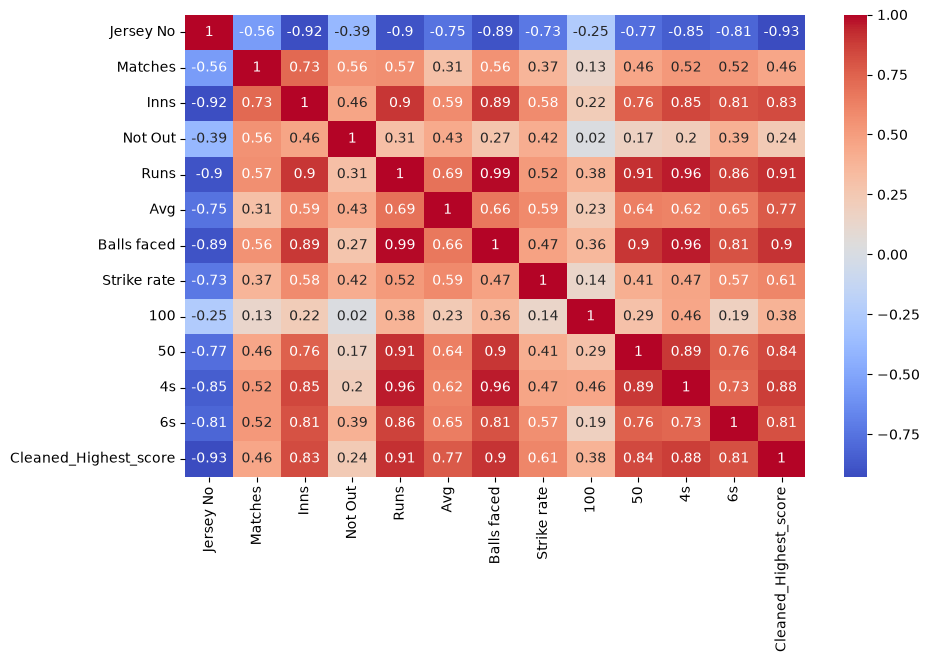

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
correlation=data.corr(numeric_only=True)
plt.figure(figsize=(10,6))
sns.heatmap(correlation,annot=True,cmap='coolwarm')
plt.show()

# Q8. Check the list of players who has an average greater than 50 as well strike rate above 125. Print player name, average and strike rate.

In [30]:
result=data[(data['Avg']>50)&(data['Strike rate']>150)]
result[['Player','Avg','Strike rate']]

,Player,Avg,Strike rate
31,Kieron Pollard,53.6,191.42


# Q9. Please check the list of players who has an average greater than 40 and balls faced above 100. Print player name, average and balls faced.

In [33]:
result=data[(data['Avg']>40)&(data['Balls faced']>100)]
result[['Player','Avg','Balls faced']]


,Player,Avg,Balls faced
0,KL Rahul,55.83,518
1,Shikhar Dhawan,44.14,427
4,Ishan Kishan,57.33,354
8,Virat Kohli,42.36,384
9,ABD Villiers,45.40,286
10,Faf Duplessis,40.81,319
14,Eoin Morgan,41.80,302
24,Kane Williamson,45.28,237
27,Chris Gayle,41.14,210
28,Ben Stokes,40.71,200


# Q10. Players who scored atleast one century in this season. Create visualization.

In [46]:

result=data[data[100]>=1]
result[['Player',100]]



,Player,100
0,KL Rahul,1
1,Shikhar Dhawan,2
13,Mayank Agarwal,1
28,Ben Stokes,1


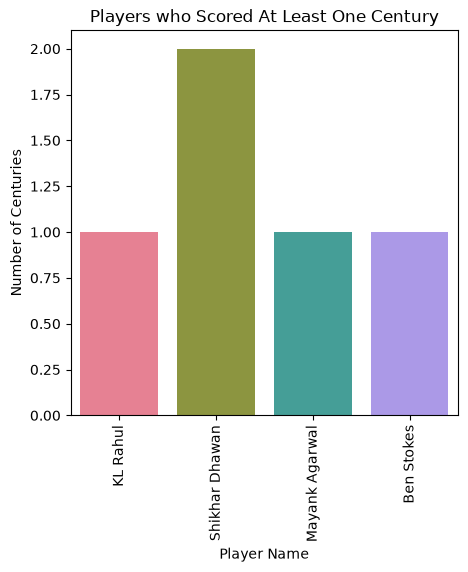

In [55]:
plt.figure(figsize=(5,5))
sns.barplot(data=result,x='Player',y=100,palette='husl', hue='Player', legend=False)
plt.xticks(rotation=90)
plt.title('Players who Scored At Least One Century')
plt.xlabel('Player Name')
plt.ylabel('Number of Centuries')
plt.show()


# Q11. Players who scored atleast 4 half centuries in this season.


In [44]:
result=data[data[50]>=4]
result[['Player',50]]

,Player,50
0,KL Rahul,5
1,Shikhar Dhawan,4
2,David Warner,4
4,Ishan Kishan,4
5,Quinton Kock,4
6,Suryakumar Yadav,4
7,Devdutt Padikkal,5
9,ABD Villiers,5
10,Faf Duplessis,4


# Q12. Check the list of players who hit more than 45 boundaries and more than 10 sixes in this season.

In [56]:
data.columns


Index([            'Jersey No',                'Player',
                     'Matches',                  'Inns',
                     'Not Out',                  'Runs',
               'Highest Score',                   'Avg',
                 'Balls faced',           'Strike rate',
                           100,                      50,
                          '4s',                    '6s',
                  'First Name',             'Last Name',
       'Cleaned_Highest_score'],
      dtype='object')

In [62]:
result=data[(data['4s']>=45) & (data['6s']>=10)]
result[['Player','4s','6s']]

,Player,4s,6s
0,KL Rahul,58,23
1,Shikhar Dhawan,67,12
2,David Warner,52,14
5,Quinton Kock,46,22
6,Suryakumar Yadav,61,11


# Q13. Plot a histogram of number of matches played in a season by players.

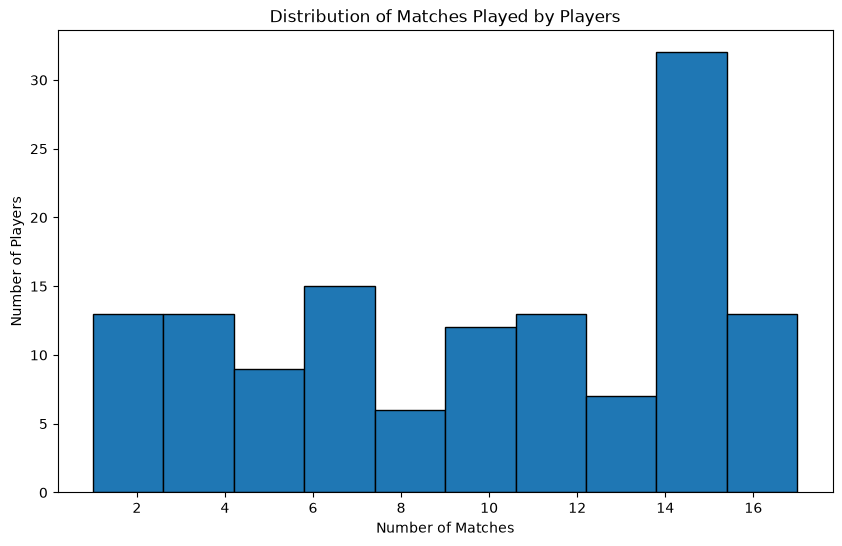

In [68]:
plt.figure(figsize=(10,6))
plt.hist(data['Matches'],bins=10,edgecolor='black')
plt.title('Distribution of Matches Played by Players')
plt.xlabel('Number of Matches')
plt.ylabel('Number of Players')
plt.show()

# Q14. Plot the histogram of balls faced by players.

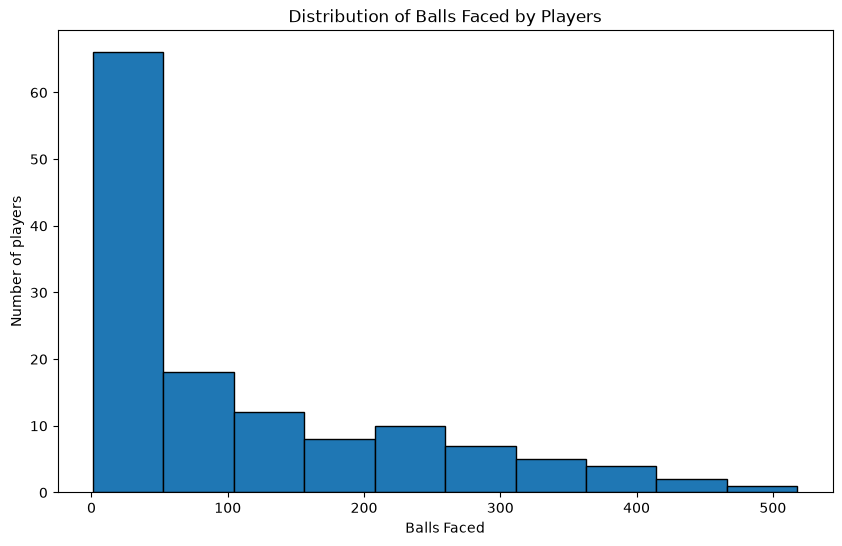

In [70]:
plt.figure(figsize=(10,6))
plt.hist(data['Balls faced'],bins=10,edgecolor='black')
plt.title('Distribution of Balls Faced by Players')
plt.xlabel('Balls Faced')
plt.ylabel('Number of players')
plt.show()

# Q15. Top 12 players with most runs in a season.

In [73]:
result=data.sort_values(by='Runs',ascending=False)
top_12=result.head(12)
top_12[['Player','Runs']]

,Player,Runs
0,KL Rahul,670
1,Shikhar Dhawan,618
2,David Warner,548
3,Shreyas Iyer,519
4,Ishan Kishan,516
5,Quinton Kock,503
6,Suryakumar Yadav,480
7,Devdutt Padikkal,473
8,Virat Kohli,466
9,ABD Villiers,454


# Q16. Print the players who played the match but didn't get the batting.

In [76]:
result=data[data['Matches']>data['Inns']]
result[['Player', 'Matches', 'Inns']]

,Player,Matches,Inns
4,Ishan Kishan,14,13
6,Suryakumar Yadav,16,15
9,ABD Villiers,15,14
12,Manish Pandey,16,15
16,Ambati Rayudu,12,11
...,...,...,...
127,Sheldon Cottrell,6,1
128,Khaleel Ahmed,7,1
129,Arshdeep Singh,8,1
130,Daniel Sams,3,1



 # Q17. Create a new column to show the percentage of total runs scored in 4s and 6s. Then print the top 5 players with maximum percentage.

In [78]:
data['Boundary_Runs'] = (data['4s'] * 4) + (data['6s'] * 6)
data['Boundary_Percentage'] = (data['Boundary_Runs'] / data['Runs']) * 100
result = data.sort_values(by='Boundary_Percentage', ascending=False)
top_5 = result.head(5)
top_5[['Player', 'Runs', 'Boundary_Runs', 'Boundary_Percentage']]

,Player,Runs,Boundary_Runs,Boundary_Percentage
109,Andrew Tye,6,6,100.000000
48,Andre Russell,117,90,76.923077
74,Chris Morris,34,26,76.470588
29,Hardik Pandya,281,206,73.309609
47,Sunil Narine,121,88,72.727273


# Q18. Print the players with top 5 Not out percentages (Not Out percentage can be calculated as number of Not outs divided by Innings).

In [80]:
data['Not_Out_Percentage'] = (data['Not Out'] / data['Inns']) * 100
result = data.sort_values(by='Not_Out_Percentage', ascending=False)
top_5 = result.head(5)
top_5[['Player', 'Not Out', 'Inns', 'Not_Out_Percentage']]

,Player,Not Out,Inns,Not_Out_Percentage
113,Dhawal Kulkarni,1,1,100.0
116,Rahul Chahar,1,1,100.0
115,Prasidh Krishna,2,2,100.0
62,Gurkeerat Singh,5,5,100.0
68,Lockie Ferguson,2,2,100.0


#  Q19. Create visualization of top 10 players with highest number of sixes.

In [81]:
result = data.sort_values(by='6s', ascending=False)
top_10 = result.head(10)
top_10[['Player', '6s']]

,Player,6s
4,Ishan Kishan,30
15,Sanju Samson,26
17,Nicholas Pooran,25
29,Hardik Pandya,25
14,Eoin Morgan,24
27,Chris Gayle,23
9,ABD Villiers,23
0,KL Rahul,23
5,Quinton Kock,22
31,Kieron Pollard,22


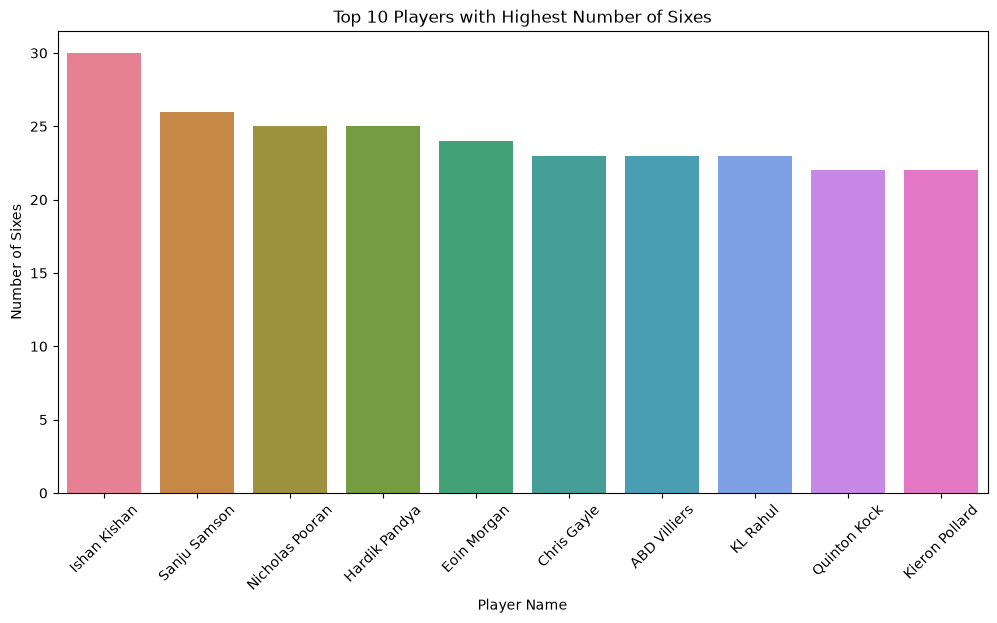

In [82]:
plt.figure(figsize=(12, 6))

sns.barplot(data=top_10, x='Player', y='6s',
            hue='Player', palette='husl', legend=False)

plt.xticks(rotation=45)
plt.title('Top 10 Players with Highest Number of Sixes')
plt.xlabel('Player Name')
plt.ylabel('Number of Sixes')

plt.show()

# Q20. Scatter plot of runs scored by a player v/s balls faced in a season. Then find the relationship between these 2 variables.

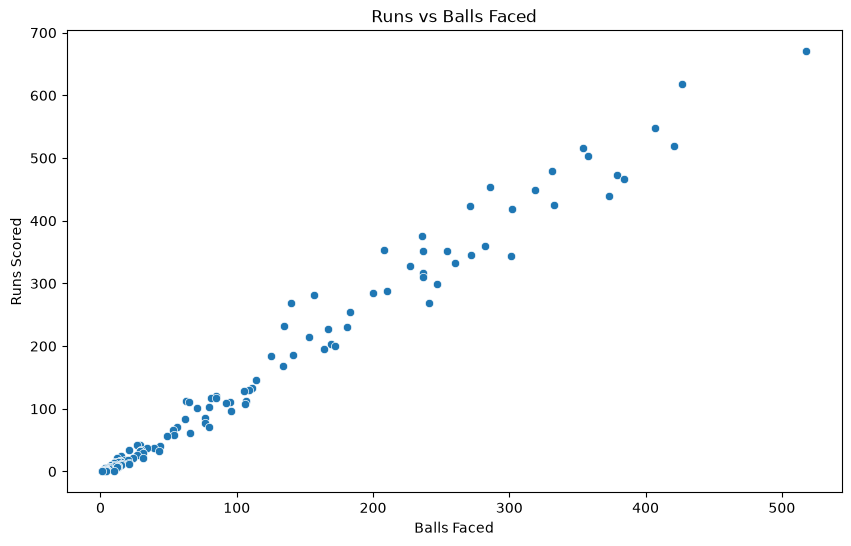

In [83]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=data, x='Balls faced', y='Runs')

plt.title('Runs vs Balls Faced')
plt.xlabel('Balls Faced')
plt.ylabel('Runs Scored')

plt.show()

In [84]:
data['Balls faced'].corr(data['Runs'])

np.float64(0.9899480233860843)